# MLIP Studio Python API — Google Colab showcase

This notebook installs MLIP Studio using the same custom dependency order documented in the repository, clones the source, installs the API with `--no-deps`, and demonstrates every currently public task API.

Before running it, select **Runtime → Change runtime type → T4 GPU** (or another GPU). NOTE: Use runtime version 2025.10.
The full model stack is large and installation/model downloads can take a while. UMA/eSEN may require prior Hugging Face license approval and login. Individual gated-model sections catch access errors so the rest of the notebook can still run.

Model predictions are examples, not reference-quality scientific results. Always choose a model trained for the relevant chemical/material domain and review its license and citation.

In [1]:
import platform
import shutil
import subprocess
import sys

print("Python:", sys.version)
print("Platform:", platform.platform())
if shutil.which("nvidia-smi"):
    subprocess.run(["nvidia-smi"], check=False)
else:
    print("No NVIDIA GPU detected. The examples will use CPU and may be slow.")

Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.35


## 1. Clone MLIP Studio

In [2]:
from pathlib import Path
import subprocess

REPO_URL = "https://github.com/mlipstudio/MLIP-Studio.git"
if Path("/kaggle/working").is_dir():
    RUNTIME_DIR = Path("/kaggle/working")
elif Path("/content").is_dir():
    RUNTIME_DIR = Path("/content")
else:
    RUNTIME_DIR = Path.cwd()
REPO_DIR = RUNTIME_DIR / "MLIP-Studio"

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    print(f"Using existing checkout: {REPO_DIR}")

print("Repository:", REPO_DIR)

Repository: /content/MLIP-Studio


## 2. Install system and Python dependencies

These commands intentionally mirror the README/Docker installation order. Several packages are installed with `--no-deps` because their upstream dependency metadata conflicts with the combined MLIP environment.

In [3]:
!apt-get -qq update
!apt-get -qq install -y build-essential git swig libopenbabel-dev openbabel

W: An error occurred during the signature verification. The repository is not updated and the previous index files will be used. GPG error: https://cli.github.com/packages stable InRelease: The following signatures couldn't be verified because the public key is not available: NO_PUBKEY 5612B36462313325
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
W: Failed to fetch https://cli.github.com/packages/dists/stable/InRelease  The following signatures couldn't be verified because the public key is not available: NO_PUBKEY 5612B36462313325
W: Some index files failed to download. They have been ignored, or old ones used instead.
(Reading database ... 126675 files and directories currently installed.)
Preparing to unpack .../0-git_1%3a2.34.1-1ubuntu1.17_amd64.deb ...
Unpacking git (1:2.34.1-1ubuntu1.17) over (1:2.34.1-1ubuntu1.15) ...
Selecting previousl

In [4]:
%pip install --upgrade pip
%pip install --no-deps fairchem-core==2.16.0 --ignore-requires-python
requirements_file = str(REPO_DIR / "requirements.txt")
%pip install -r "$requirements_file"
%pip install --no-deps "upet@git+https://github.com/lab-cosmo/upet.git" --ignore-requires-python
%pip install --no-deps "git+https://github.com/WillBaldwin0/graph_electrostatics.git@v0.4.0" --ignore-requires-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 39.3 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
  Cloning https://github.com/manassharma07/mace_e3nn_new.git (to revision main) to /tmp/pip-install-naaezbj0/mace-e3nn-new_7b1a9d28199a44ad8925fcc93e510dc6
  Running command git clone --filter=blob:none --quiet https://github.com/manassharma07/mace_e3nn_new.git /tmp/pip-install-naaezbj0/mace-e3nn-new_7b1a9d28199a44ad8925fcc93e510dc6
  Resolved https://github.com/manassharma07/mace_e3nn_new.git to commit 523668587de88291af5fcfe324c808ec48d41781
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/microsoft/mattersim.git to /tmp/pip-req-build-jj3pa2pw
  Running command git clone --filter=blob:none --quiet https://github.com/microsoft/mattersim.git /tmp/pip-req-bu

  Cloning https://github.com/lab-cosmo/upet.git to /tmp/pip-install-2gw7k8_7/upet_ff366aecc83d4aa4b9aa354161b584da
  Running command git clone --filter=blob:none --quiet https://github.com/lab-cosmo/upet.git /tmp/pip-install-2gw7k8_7/upet_ff366aecc83d4aa4b9aa354161b584da
  Resolved https://github.com/lab-cosmo/upet.git to commit 377353a75a8d501833a8a18b55fa91ba89a6cc16
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for upet: filename=upet-0.3.2.dev3+g377353a75-py3-none-any.whl size=47877 sha256=93309dc39bfa9bf321a78101ee6dcb01c55049ed3e9d35de9748bd948b4a0803
  Stored in directory: /tmp/pip-ephem-wheel-cache-m5__ylrd/wheels/7b/14/b3/14661d0cd12a9f10d7ee4348ed69e403d1a5932a366a0647a6
Successfully built upet
  Cloning https://github.com/WillBaldwin0/graph_electrostatics.git (to revision v0.4.0) to /tmp/pip-req-build-se62gj9g
  Running command git clone --filter=blob:none --quiet https:/

## 3. Install the API

Install from the repository root, not from inside the `mlipstudio/` package directory. Hosted notebooks use a regular installation rather than editable mode so the package is immediately importable from any working directory.

In [5]:
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--no-deps",
        "--force-reinstall",
        str(REPO_DIR),
    ],
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '--no-deps', '--force-reinstall', '/content/MLIP-Studio'], returncode=0)

### Optional Hugging Face login

Set `LOGIN_TO_HUGGING_FACE = True` if you have accepted the UMA/eSEN model terms and want to run the spin-determination example. Colab will display a secure token prompt.

In [6]:
LOGIN_TO_HUGGING_FACE = False

if LOGIN_TO_HUGGING_FACE:
    from huggingface_hub import notebook_login

    notebook_login()
else:
    print("Skipping Hugging Face login. Set the flag above to run gated models.")

Skipping Hugging Face login. Set the flag above to run gated models.


## 4. Import the API and inspect the model catalog

In [7]:
import gc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from ase.build import bulk, molecule

import mlipstudio

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("MLIP Studio API:", mlipstudio.__version__)
print("Device:", DEVICE)
print("Installed from:", Path(mlipstudio.__file__).resolve())

def release_unused_resources():
    """Collect objects after the caller deletes its calculator variable."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

MLIP Studio API: 0.1.0.dev0
Device: cuda
Installed from: /usr/local/lib/python3.12/dist-packages/mlipstudio/__init__.py


In [8]:
catalog = pd.DataFrame(
    {
        "name": spec.name,
        "family": spec.family,
        "kind": spec.calculator_kind,
        "required_parameters": ", ".join(spec.required_parameters),
    }
    for spec in mlipstudio.list_models()
)
display(catalog)
print(catalog.groupby("family").size())

,name,family,kind,required_parameters
0,MACE MPA Medium,MACE,ase,
1,MACE OMAT Medium,MACE,ase,
2,MACE OMAT Small,MACE,ase,
3,MACE MATPES r2SCAN Medium,MACE,ase,
4,MACE MATPES PBE Medium,MACE,ase,
...,...,...,...,...
60,7net-mf-ompa,SevenNet,ase,modal
61,7net-omni,SevenNet,ase,modal
62,AIMNet2 (wB97M-D3),AIMNet2,ase,
63,AIMNet2 (B97-3c),AIMNet2,ase,


family
AIMNet2       2
FairChem      5
In-House      1
MACE         24
MatterSim     2
ORB          10
SevenNet      5
UPET         16
dtype: int64


## 5. MACE materials workflow

One loaded MACE calculator is reused for single-point prediction, geometry optimization, and cohesive energy. This avoids downloading and loading the same checkpoint repeatedly.

In [9]:
cu = bulk("Cu", crystalstructure="fcc", a=3.62).repeat((2, 2, 2))
mace_calculator = mlipstudio.create_calculator(
    "MACE MPA Medium",
    device=DEVICE,
)
print(cu, mace_calculator.__class__.__name__)

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using medium MPA-0 model as default MACE-MP model, to use previous (before 3.10) default model please specify 'medium' as model argument
Downloading: 100.0% (75.8 MB / 75.8 MB)
Cached MACE model to /root/.cache/mace/macempa0mediummodel
Using Materials Project MACE for MACECalculator with /root/.cache/mace/macempa0mediummodel
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/usr/local/lib/python3.12/dist-packages/mace/calculators/mace.py:207: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Atoms(symbols='Cu8', pbc=True, cell=[[0.0, 3.62, 3.62], [3.62, 0.0, 3.62], [3.62, 3.62, 0.0]]) MACECalculator


### 5.1 Single-point energy, forces, and stress

In [10]:
single_point = mlipstudio.SinglePointTask(
    properties=("energy", "forces", "stress"),
)
single_result = single_point.calculate(cu, mace_calculator)

print(f"Energy: {single_result.energy:.6f} eV")
print(f"Maximum force: {single_result.max_force:.6f} eV/Angstrom")
print("Stress (ASE Voigt order, eV/Angstrom^3):", single_result.stress)
print(f"Runtime: {single_result.runtime_seconds:.3f} s")

Energy: -32.796616 eV
Maximum force: 0.000000 eV/Angstrom
Stress (ASE Voigt order, eV/Angstrom^3): [-1.38413897e-02 -1.38413813e-02 -1.38413487e-02  4.84049867e-09
  1.38315637e-09  6.57359889e-10]
Runtime: 1.732 s


### 5.2 Geometry optimization

In [11]:
distorted_cu = cu.copy()
distorted_cu.positions[0] += [0.10, -0.06, 0.04]

optimization = mlipstudio.OptimizationTask(
    optimizer="LBFGS",
    fmax=0.05,
    steps=30,
    record_trajectory=True,
)
optimization_result = optimization.calculate(distorted_cu, mace_calculator)

print("Converged:", optimization_result.converged)
print("Steps:", optimization_result.steps)
print(f"Final energy: {optimization_result.energy:.6f} eV")
print(f"Final maximum force: {optimization_result.atomic_max_force:.6f} eV/Angstrom")
print("Recorded frames:", len(optimization_result.trajectory))

Converged: True
Steps: 8
Final energy: -32.796146 eV
Final maximum force: 0.046787 eV/Angstrom
Recorded frames: 10


### 5.3 Cohesive energy

For non-FairChem calculators, MLIP Studio evaluates one isolated atom per unique element and records those values in the result. Periodic input selects cohesive energy automatically.

In [12]:
cohesive_result = mlipstudio.AtomizationCohesiveEnergyTask().calculate(
    cu,
    mace_calculator,
)

print("Type:", cohesive_result.calculation_type)
print(f"Cohesive energy: {cohesive_result.cohesive_energy_eV_per_atom:.6f} eV/atom")
print("Reference source:", cohesive_result.reference_source)
print("Isolated-atom references:", cohesive_result.isolated_atom_energies_eV)

Type: cohesive
Cohesive energy: 3.499318 eV/atom
Reference source: calculated-with-system-calculator
Isolated-atom references: {29: -0.600258469581604}


### 5.4 Hessian, vibrations, EOS, batch calculations, and specialist optimizers

These tasks use the same loaded MACE calculator. Vibrational displacements run in an automatically cleaned temporary directory.

In [13]:
hydrogen = molecule("H2")
hessian_result = mlipstudio.MACEHessianTask().calculate(
    hydrogen, mace_calculator
)
print("Hessian shape:", hessian_result.hessian_eV_per_A2.shape)
print("Symmetry error:", hessian_result.symmetry_error_eV_per_A2)

Hessian shape: (6, 6)
Symmetry error: 0.0


In [14]:
vibration_result = mlipstudio.VibrationalModeTask().calculate(
    hydrogen, mace_calculator
)
print("Frequencies (cm^-1):", vibration_result.frequencies_cm_minus1)
print("Zero-point energy (eV):", vibration_result.zero_point_energy_eV)

Frequencies (cm^-1): [0.00000000e+00+6.04765048e+02j 0.00000000e+00+6.04764820e+02j
 0.00000000e+00+1.74025994e-05j 0.00000000e+00+0.00000000e+00j
 7.88281841e-06+0.00000000e+00j 4.48465685e+03+0.00000000e+00j]
Zero-point energy (eV): 0.2780132897879605


In [15]:
eos_result = mlipstudio.EquationOfStateTask().calculate(cu, mace_calculator)
print("Equilibrium volume (A^3):", eos_result.equilibrium_volume_A3)
print("Bulk modulus (GPa):", eos_result.bulk_modulus_GPa)

Equilibrium volume (A^3): 96.4437991604904
Bulk modulus (GPa): 130.32149217434232


In [16]:
batch_structures = [bulk("Cu", "fcc", a=3.60), bulk("Cu", "fcc", a=3.65)]
batch_single = mlipstudio.BatchEnergyForceStressTask().calculate(
    batch_structures, mace_calculator
)
for item in batch_single.successful_items:
    print(item.label, item.result.energy, item.result.max_force)

batch_atomization = mlipstudio.BatchAtomizationEnergyTask().calculate(
    [molecule("H2"), molecule("H2O")], mace_calculator
)
for item in batch_atomization.successful_items:
    print(item.label, item.result.atomization_energy_eV)

Cu_1 -4.095426559448242 0.0
Cu_2 -4.100576400756836 0.0
H2_1 4.280366897583008
H2O_2 10.002858757972717


In [17]:
for optimizer_name in (
    "Lindh Hessian LBFGS",
    "MACE Hessian LBFGS",
    "MACE-Seed LBFGS",
):
    trial = molecule("H2")
    trial.positions[1, 2] += 0.10
    optimized = mlipstudio.OptimizationTask(
        optimizer=optimizer_name, fmax=0.05, steps=5
    ).calculate(trial, mace_calculator)
    print(optimizer_name, optimized.steps, optimized.atomic_max_force)

Lindh Hessian LBFGS 3 0.012412890791893005
MACE Hessian LBFGS 3 0.02089015580713749
MACE-Seed LBFGS 3 0.02089015580713749


In [18]:
consensus_models = {
    "MPA": mace_calculator,
    "MP": mlipstudio.CalculatorFactory(
        "MACE MP 0b2 Small", device=DEVICE
    ),
}
consensus = mlipstudio.ModelConsensusTask().calculate(cu, consensus_models)
print("Energy range (eV/atom):", consensus.energy_range_eV_per_atom)
print("Maximum force disagreement (eV/A):", consensus.max_force_disagreement_eV_per_A)

Downloading: 100.0% (64.5 MB / 64.5 MB)
Cached MACE model to /root/.cache/mace/macesmalldensityagnesistressmodel
Using Materials Project MACE for MACECalculator with /root/.cache/mace/macesmalldensityagnesistressmodel
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/usr/local/lib/python3.12/dist-packages/mace/calculators/mace.py:207: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Energy range (eV/atom): 0.008879661560058594
Maximum force disagreement (eV/A): 1.183798516230017e-07


In [19]:
del mace_calculator
release_unused_resources()
print("Released the materials calculator.")

Released the materials calculator.


## 6. HOMO–LUMO gap with the bundled QM9 model

`QM9-Gap` supports non-periodic molecules containing only H, C, N, O, and F. It is packaged with MLIP Studio and does not download a separate checkpoint.

In [20]:
methane = molecule("CH4")
qm9_calculator = mlipstudio.create_calculator("QM9-Gap", device=DEVICE)
gap_result = mlipstudio.HOMOLUMOGapTask().calculate(methane, qm9_calculator)

print(f"Predicted HOMO-LUMO gap: {gap_result.gap_eV:.6f} eV")
print(f"Runtime: {gap_result.runtime_seconds:.3f} s")
del qm9_calculator
release_unused_resources()

Predicted HOMO-LUMO gap: 13.629583 eV
Runtime: 0.009 s


## 7. MACE-POLAR molecular workflow

The MACE-POLAR checkpoint is reused for dipole/partial-charge prediction and molecular atomization energy. Review its Academic Software License before use.

In [21]:
water = molecule("H2O")
polar_calculator = None
try:
    polar_calculator = mlipstudio.create_calculator(
        "MACE POLAR 1 S",
        device=DEVICE,
    )
    print("Loaded MACE POLAR 1 S.")
except Exception as exc:
    print("MACE-POLAR could not be loaded; its two examples will be skipped.")
    print(type(exc).__name__, exc)

Downloading: 100.0% (31.8 MB / 31.8 MB)
Cached MACE model to /root/.cache/mace/MACEPOLAR1Smodel
Using Materials Project MACE for MACECalculator with /root/.cache/mace/MACEPOLAR1Smodel
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/usr/local/lib/python3.12/dist-packages/mace/calculators/mace.py:207: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loaded MACE POLAR 1 S.


### 7.1 Dipole moment and partial charges

In [22]:
if polar_calculator is not None:
    dipole_result = mlipstudio.DipoleMomentTask(
        charge=0,
        spin_multiplicity=1,
        external_field=(0.0, 0.0, 0.0),
    ).calculate(water, polar_calculator)

    print("Dipole vector (e*Angstrom):", dipole_result.dipole_eA)
    print(f"Dipole magnitude: {dipole_result.dipole_magnitude_eA:.6f} e*Angstrom")
    charges = pd.DataFrame(
        {
            "symbol": water.get_chemical_symbols(),
            "partial_charge_e": dipole_result.partial_charges_e,
        }
    )
    display(charges)
    print("Sum of partial charges:", dipole_result.total_partial_charge_e)
else:
    print("Skipped because MACE-POLAR was not loaded.")

Dipole vector (e*Angstrom): [ 0.          0.         -0.33241242]
Dipole magnitude: 0.332412 e*Angstrom


,symbol,partial_charge_e
0,O,-0.557450
1,H,0.278725
2,H,0.278725


Sum of partial charges: 0.0


### 7.2 Molecular atomization energy

Non-periodic input selects atomization energy. The default isolated-atom metadata mirrors MLIP Studio's GUI; for production work, provide explicit model-appropriate references or override `isolated_atom_metadata`.

In [23]:
if polar_calculator is not None:
    atomization_result = mlipstudio.AtomizationCohesiveEnergyTask().calculate(
        water,
        polar_calculator,
    )

    print("Type:", atomization_result.calculation_type)
    print(f"Atomization energy: {atomization_result.atomization_energy_eV:.6f} eV/molecule")
    print("Reference source:", atomization_result.reference_source)
    print("Stoichiometry by atomic number:", atomization_result.stoichiometry)
    print("Isolated-atom references:", atomization_result.isolated_atom_energies_eV)
else:
    print("Skipped because MACE-POLAR was not loaded.")

if polar_calculator is not None:
    del polar_calculator
    release_unused_resources()

Type: atomization
Atomization energy: 9.821928 eV/molecule
Reference source: calculated-with-system-calculator
Stoichiometry by atomic number: {8: 1, 1: 2}
Isolated-atom references: {1: -15.201767921447754, 8: -2039.6378173828125}


## 8. Spin determination with UMA-OMOL

This section requires Hugging Face access to UMA. Set the login flag near the top of the notebook after accepting the upstream terms. The task resets calculator result caches between multiplicities because ASE does not regard `atoms.info` changes as structural changes.

In [24]:
uma_calculator = None
try:
    uma_calculator = mlipstudio.create_calculator(
        "UMA Small 1.2",
        device=DEVICE,
        task_name="omol",
    )
    spin_result = mlipstudio.SpinDeterminationTask(
        charge=0,
        multiplicities=(1, 3, 5),
        continue_on_error=True,
    ).calculate(water, uma_calculator)

    spin_table = pd.DataFrame(
        {
            "multiplicity": state.multiplicity,
            "total_spin": state.total_spin,
            "energy_eV": state.energy_eV,
            "runtime_s": state.runtime_seconds,
            "error": state.error,
        }
        for state in spin_result.states
    )
    display(spin_table)
    print("Optimal multiplicity:", spin_result.optimal_state.multiplicity)
    print("Minimum energy (eV):", spin_result.optimal_state.energy_eV)
except Exception as exc:
    print("UMA spin example skipped. Log in and verify model approval to run it.")
    print(type(exc).__name__, exc)
finally:
    if uma_calculator is not None:
        del uma_calculator
        release_unused_resources()

UMA spin example skipped. Log in and verify model approval to run it.
ModelLoadError Failed to initialize UMA Small 1.2: 401 Client Error. (Request ID: Root=1-6acfcdda-521c57ce144defce0eb2fc13;9d9ff083-aa06-47c3-8ef1-46bac65bcd4b)

Cannot access gated repo for url https://huggingface.co/facebook/UMA/resolve/main/checkpoints/uma-s-1p2.pt.
Access to model facebook/UMA is restricted. You must have access to it and be authenticated to access it. Please log in.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


## 9. Band gap and density of states with PET-MAD-DOS

PET-MAD-DOS is a task-specific CPU provider, not a general ASE energy/force calculator. Its first run downloads its upstream model resources. MLIP Studio's `BandGapDOSTask` supports the current UPET result-dictionary API as well as the older three-method API.

models/pet-mad-dos-v1.0.ckpt:   0%|          | 0.00/135M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2346: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2346: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

models/bandgap-model.pt:   0%|          | 0.00/4.74M [00:00<?, ?B/s]

models/fermi-model.pt:   0%|          | 0.00/4.74M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/metatomic_ase/_neighbors.py:78: UserWarning: `compute_requested_neighbors_from_options` is deprecated and will be removed in a future version. Please use `neighbor_lists_for_model` to get the calculators and call them directly.
  vesin.metatomic.compute_requested_neighbors_from_options(


Band gap: 0.502147 eV
Fermi level: 150.911346 eV
DOS points: 4806


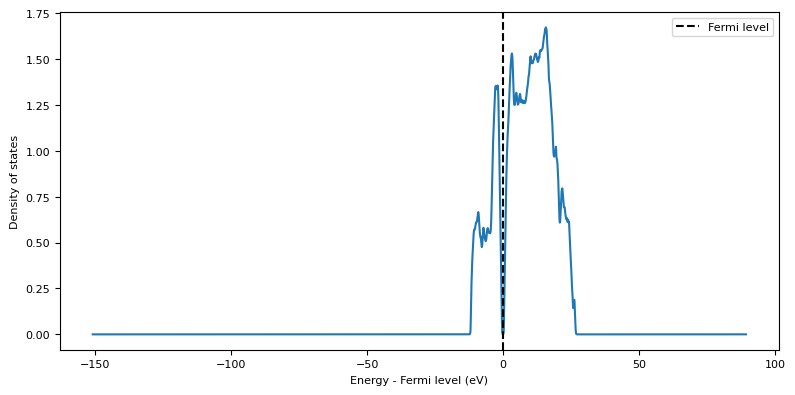

In [25]:
silicon = bulk("Si", crystalstructure="diamond", a=5.43)
dos_calculator = mlipstudio.create_calculator(
    "PET-MAD-DOS",
    device="cpu",
    version="latest",
)
dos_task = mlipstudio.BandGapDOSTask()
dos_result = dos_task.calculate(silicon, dos_calculator)

print(f"Band gap: {dos_result.band_gap_eV:.6f} eV")
print(f"Fermi level: {dos_result.fermi_level_eV:.6f} eV")
print(f"DOS points: {len(dos_result.density_of_states)}")

plt.figure(figsize=(8, 4))
plt.plot(
    dos_result.energies_relative_to_fermi_eV,
    dos_result.density_of_states,
)
plt.axvline(0.0, color="black", linestyle="--", label="Fermi level")
plt.xlabel("Energy - Fermi level (eV)")
plt.ylabel("Density of states")
plt.legend()
plt.tight_layout()
plt.show()

del dos_calculator
release_unused_resources()

## 10. Batch HOMO-LUMO prediction

The batch wrapper preserves input order and records individual failures instead of losing the entire batch.

In [26]:
qm9_calculator = mlipstudio.create_calculator("QM9-Gap", device=DEVICE)
gap_batch = mlipstudio.BatchHOMOLUMOGapTask().calculate(
    [molecule("CH4"), molecule("H2O")], qm9_calculator
)
for item in gap_batch.successful_items:
    print(item.label, item.result.gap_eV)
del qm9_calculator
release_unused_resources()

CH4_1 13.629583358764648
H2O_2 9.849166870117188


## 11. Where to go next

All task objects follow the same pattern: configure the task, then call `task.calculate(atoms, calculator)`. Results contain raw numerical arrays/scalars in documented ASE units and calculator-free copies of structures.

This notebook covered:

- `SinglePointTask`
- `OptimizationTask`
- `AtomizationCohesiveEnergyTask` for both cohesive and atomization energy
- `HOMOLUMOGapTask`
- `DipoleMomentTask`
- `SpinDeterminationTask`
- `BandGapDOSTask`
- `MACEHessianTask`
- `VibrationalModeTask`
- `EquationOfStateTask`
- `ModelConsensusTask`
- batch single-point, HOMO-LUMO, and atomization/cohesive tasks

Use `mlipstudio.list_models()` and `mlipstudio.get_model_spec(name)` for programmatic discovery. Reuse a loaded calculator sequentially when possible, but create independent calculators for parallel workers or future NEB image calculations.